# 03 · Gait events & spatiotemporal labels

* Fukuchi treadmill: **force-plate events** (Fy > 30 N, both belts) — gold standard (subjects 43–51
  have a dead left belt → Zeni fallback).
* Everything else: **Zeni et al. 2008** coordinate algorithm (heel / toe relative to pelvis).

This notebook quantifies Zeni vs force plates, then the label distributions (heads 2–5).

*This project is a prototype and is not medical advice.*

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from analysis import *
from canonical import J, JOINTS, SIDES
style()
pd.set_option("display.width", 200, "display.max_columns", 40)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


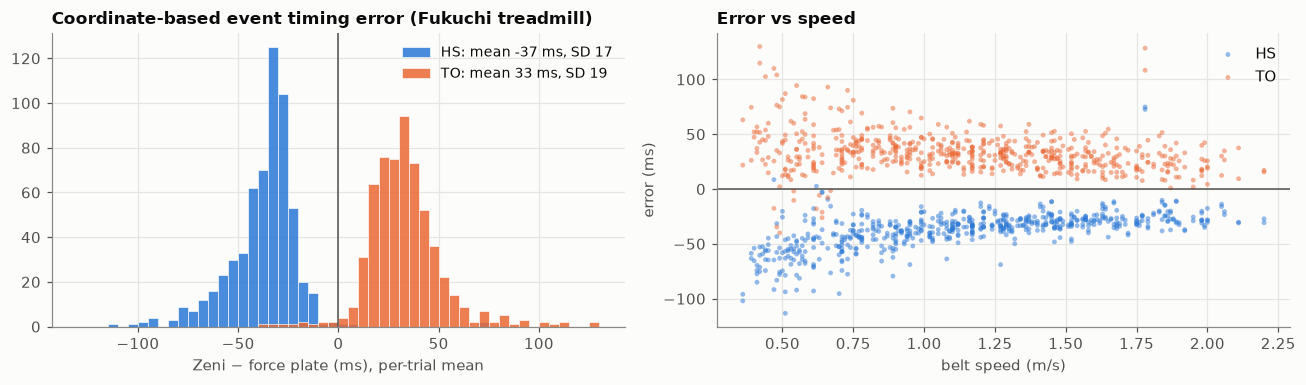

,count,mean,std,min,25%,50%,75%,max
event,,,,,,,,
HS_L,298.0,-35.4,15.5,-96.0,-42.6,-33.1,-28.0,74.8
HS_R,299.0,-39.5,18.3,-113.3,-47.4,-35.0,-28.4,72.6
TO_L,298.0,24.9,13.9,-40.0,18.0,24.6,33.0,108.3
TO_R,299.0,41.3,19.0,-1.9,29.8,37.9,48.3,130.0


In [2]:
F = trials("fukuchi", True); FT = F[F["mode"] == "treadmill"]
cols = [c for c in FT if c.startswith("zeni_err_ms_")]
E = FT[cols + ["speed", "age_group"]].melt(["speed", "age_group"], var_name="event", value_name="err").dropna()
E["event"] = E.event.str.replace("zeni_err_ms_", "")
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
for i, ev in enumerate(["HS", "TO"]):
    v = E[E.event.str.startswith(ev)].err
    axs[0].hist(v, bins=np.arange(-130, 131, 5), color=SERIES[i], alpha=0.85, label=f"{ev}: mean {v.mean():.0f} ms, SD {v.std():.0f}",
                edgecolor=SURFACE, linewidth=0.5)
axs[0].axvline(0, color=INK2, lw=1); axs[0].set_xlabel("Zeni − force plate (ms), per-trial mean")
axs[0].set_title("Coordinate-based event timing error (Fukuchi treadmill)"); axs[0].legend(fontsize=9)
for i, ev in enumerate(["HS", "TO"]):
    g = E[E.event.str.startswith(ev)]
    axs[1].scatter(g.speed, g.err, s=10, color=SERIES[i], alpha=0.5, label=ev, edgecolor="none")
axs[1].axhline(0, color=INK2, lw=1); axs[1].set_xlabel("belt speed (m/s)"); axs[1].set_ylabel("error (ms)")
axs[1].set_title("Error vs speed"); axs[1].legend()
fig.tight_layout(); save(fig, "03_zeni_vs_grf"); plt.show()
E.groupby("event").err.describe().round(1)

**Take-away:** Zeni heel strike is systematically early (~35 ms) and toe-off late (~30 ms) on this
marker set — stance time is inflated by ~6 % of the cycle. The bias is consistent, so it can be
corrected with offsets learned on Fukuchi before labelling Ferber/Toronto (or the event head trained
on GRF-only labels and the bias reported).

## Cadence, stance and stride variability vs speed

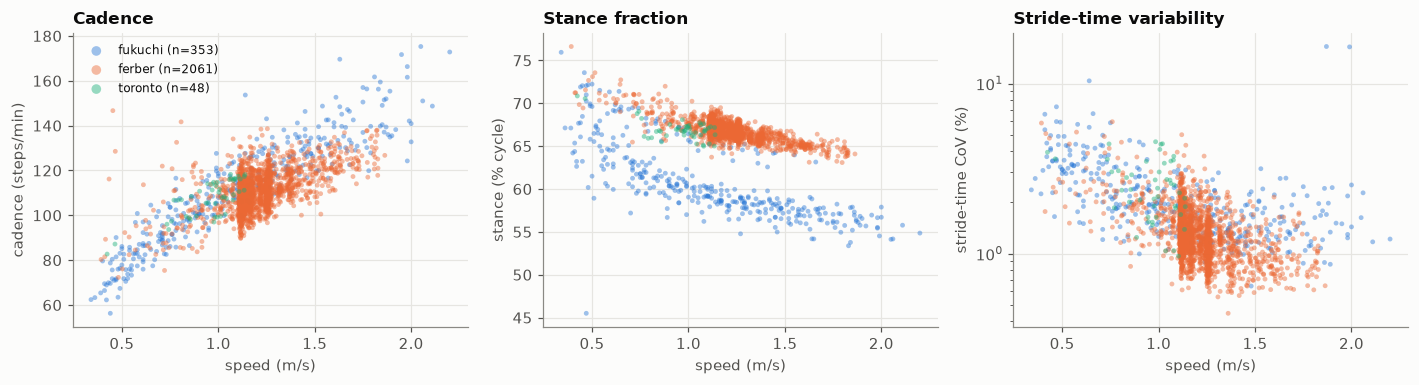

,speed,cadence,stride_time,stance_pct,double_support,stride_time_cv
dataset,,,,,,
ferber,1.16,109.92,1.09,66.92,0.37,1.26
fukuchi,1.24,113.27,1.06,64.85,0.31,1.04
toronto,0.99,108.36,1.11,66.81,0.36,2.40


In [3]:
K = all_trials()
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for d in DATASETS:
    g = K[(K.dataset == d) & (K["mode"] != "overground")]
    kw = dict(s=10, color=COL[d], alpha=0.45, edgecolor="none", label=f"{d} (n={len(g)})")
    axs[0].scatter(g.speed, g.cadence, **kw)
    axs[1].scatter(g.speed, g.stance_pct, **kw)
    axs[2].scatter(g.speed, g.stride_time_cv, **kw)
axs[0].set_ylabel("cadence (steps/min)"); axs[1].set_ylabel("stance (% cycle)"); axs[2].set_ylabel("stride-time CoV (%)")
axs[2].set_yscale("log")
for a in axs: a.set_xlabel("speed (m/s)")
axs[0].legend(fontsize=8, markerscale=2)
axs[0].set_title("Cadence"); axs[1].set_title("Stance fraction"); axs[2].set_title("Stride-time variability")
fig.tight_layout(); save(fig, "03_spatiotemporal_vs_speed"); plt.show()
K.groupby("dataset")[["speed", "cadence", "stride_time", "stance_pct", "double_support", "stride_time_cv"]].median().round(2)

Note the Fukuchi stance % split: GRF-labelled trials sit near the textbook ~60 %, Zeni-labelled
(Ferber, Toronto, Fukuchi 43–51) higher — the event bias above, not a population difference.

/tmp/nix-shell.SqEfpj/ipykernel_42674/2027375014.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(v.dropna(), positions=[i], widths=0.5, vert=False, patch_artist=True,
/tmp/nix-shell.SqEfpj/ipykernel_42674/2027375014.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(v.dropna(), positions=[i], widths=0.5, vert=False, patch_artist=True,
/tmp/nix-shell.SqEfpj/ipykernel_42674/2027375014.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(v.dropna(), positions=[i], widths=0.5, vert=False, patch_artist=True,
/tmp/nix-shell.SqEfpj/ipykernel_42674/2027375014.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in M

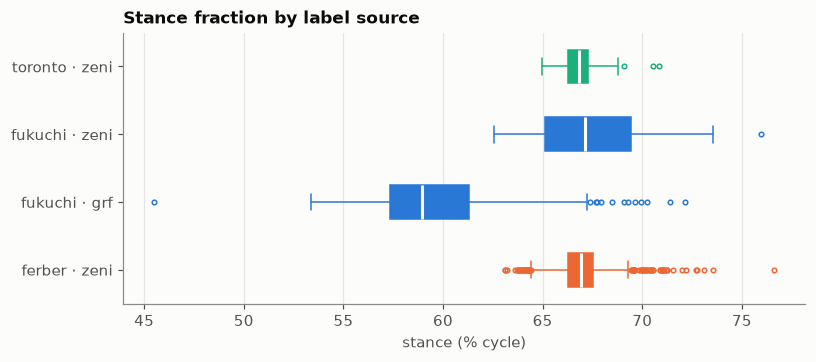

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.2))
grp = K[K["mode"] != "overground"].groupby(["dataset", "event_source"]).stance_pct
for i, ((d, src), v) in enumerate(grp):
    ax.boxplot(v.dropna(), positions=[i], widths=0.5, vert=False, patch_artist=True,
               boxprops=dict(facecolor=COL[d], color=COL[d]), medianprops=dict(color=SURFACE, lw=2),
               whiskerprops=dict(color=COL[d]), capprops=dict(color=COL[d]), flierprops=dict(markeredgecolor=COL[d], markersize=3))
ax.set_yticks(range(len(grp)), [f"{d} · {s}" for d, s in grp.groups]); ax.set_xlabel("stance (% cycle)")
ax.set_title("Stance fraction by label source"); ax.grid(axis="y", visible=False)
save(fig, "03_stance_by_source"); plt.show()

## Interlimb symmetry (head 4)
Robinson SI = 100·(L−R)/mean(L,R); 0 = symmetric. Signals of a few percent are exactly what a
physio cannot see by eye.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


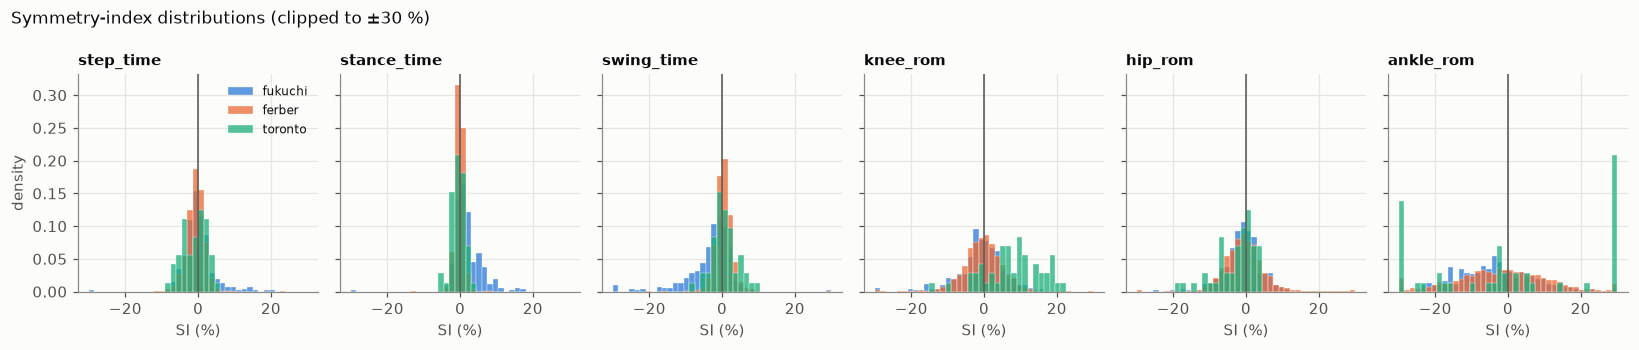

,|SI_step_time| median,|SI_stance_time| median,|SI_swing_time| median,|SI_knee_rom| median,|SI_hip_rom| median,|SI_ankle_rom| median
dataset,,,,,,
ferber,1.45,0.63,1.27,3.20,3.19,8.36
fukuchi,2.10,1.19,1.83,3.45,2.89,8.38
toronto,2.91,1.31,1.84,9.28,2.70,31.23


In [5]:
si_cols = ["SI_step_time", "SI_stance_time", "SI_swing_time", "SI_knee_rom", "SI_hip_rom", "SI_ankle_rom"]
fig, axs = plt.subplots(1, len(si_cols), figsize=(15, 3.2), sharey=True)
for a, c in zip(axs, si_cols):
    for d in DATASETS:
        v = K.loc[(K.dataset == d) & (K["mode"] != "overground"), c].dropna()
        a.hist(v.clip(-30, 30), bins=np.arange(-30, 31, 1.5), color=COL[d], alpha=0.75, density=True,
               edgecolor=SURFACE, linewidth=0.3, label=d)
    a.axvline(0, color=INK2, lw=1); a.set_title(c.replace("SI_", ""), fontsize=10); a.set_xlabel("SI (%)")
axs[0].set_ylabel("density"); axs[0].legend(fontsize=8)
fig.suptitle("Symmetry-index distributions (clipped to ±30 %)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); save(fig, "03_symmetry_distributions"); plt.show()
K.groupby("dataset")[si_cols].agg(lambda s: s.abs().median()).round(2).rename(columns=lambda c: "|" + c + "| median")

## Ferber: does symmetry track the injured side?
If SI carries clinical signal, unilateral injuries should push SI in a consistent direction
(L−R > 0 when the right is injured and the patient offloads it, or vice versa).

/tmp/nix-shell.SqEfpj/ipykernel_42674/725165795.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = a.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=False)
/tmp/nix-shell.SqEfpj/ipykernel_42674/725165795.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = a.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=False)
/tmp/nix-shell.SqEfpj/ipykernel_42674/725165795.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = a.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=False)
/tmp/nix-shell.SqEfpj/ipykernel_42674/725165795.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in

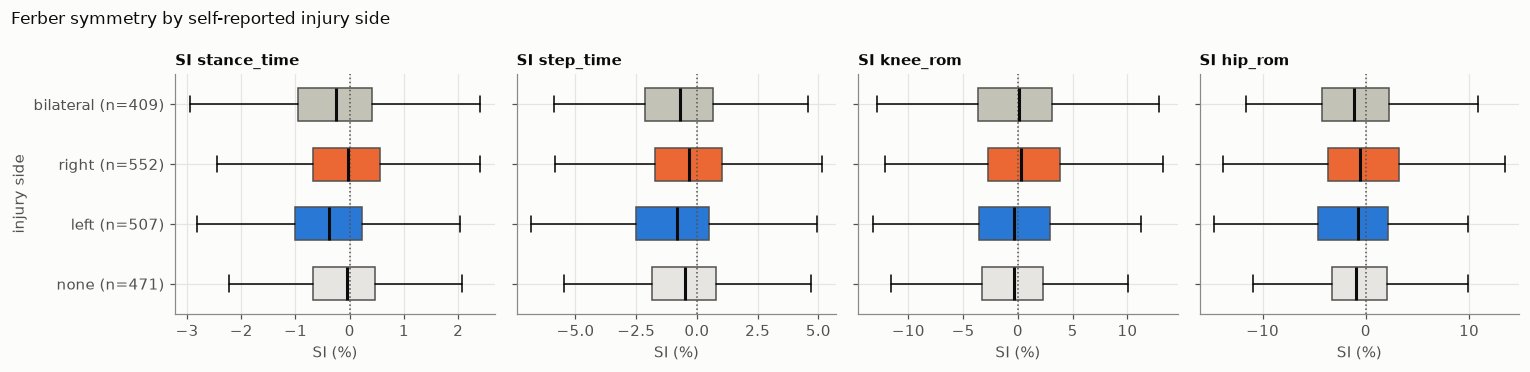

,median L-inj,median R-inj,median none,"p (L vs R, MWU)"
SI_stance_time,-0.375,-0.036,-0.043,0.000
SI_step_time,-0.824,-0.310,-0.500,0.000
SI_knee_rom,-0.352,0.271,-0.365,0.003
SI_hip_rom,-0.754,-0.550,-0.906,0.006


In [6]:
R = trials("ferber", True)
R["grp"] = R.InjSide_clean.where(R.InjSide_clean.isin(["left", "right", "bilateral", "none"]), "other")
order = ["none", "left", "right", "bilateral"]
cs = ["SI_stance_time", "SI_step_time", "SI_knee_rom", "SI_hip_rom"]
fig, axs = plt.subplots(1, len(cs), figsize=(14, 3.4), sharey=True)
for a, c in zip(axs, cs):
    data = [R.loc[R.grp == g, c].dropna().clip(-25, 25) for g in order]
    bp = a.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=False)
    for i, b in enumerate(bp["boxes"]): b.set(facecolor=[GRID, SERIES[0], SERIES[1], "#c3c2b7"][i], edgecolor=INK2)
    for m in bp["medians"]: m.set(color=INK, lw=2)
    a.axvline(0, color=INK2, lw=1, ls=":"); a.set_title(c.replace("SI_", "SI "), fontsize=10); a.set_xlabel("SI (%)")
    a.set_yticks(range(1, 5), [f"{g} (n={len(x)})" for g, x in zip(order, data)])
axs[0].set_ylabel("injury side"); fig.suptitle("Ferber symmetry by self-reported injury side", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); save(fig, "03_ferber_si_by_injside"); plt.show()
from scipy.stats import mannwhitneyu
pd.DataFrame({c: {"median L-inj": R.loc[R.grp == "left", c].median(), "median R-inj": R.loc[R.grp == "right", c].median(),
                  "median none": R.loc[R.grp == "none", c].median(),
                  "p (L vs R, MWU)": mannwhitneyu(R.loc[R.grp == "left", c].dropna(), R.loc[R.grp == "right", c].dropna()).pvalue}
              for c in cs}).T.round(3)

## Stride-to-stride view
Per-stride table (`strides.parquet`) — the unit for per-cycle regression heads.

dataset
ferber     139420
fukuchi     22382
toronto       683
dtype: int64


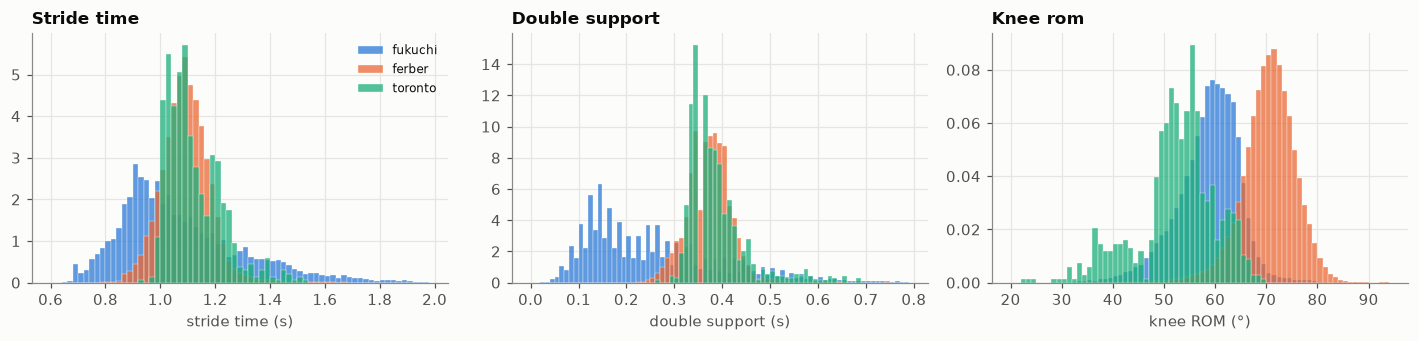

In [7]:
ST = pd.concat([strides(d) for d in DATASETS], ignore_index=True)
print(ST.groupby("dataset").size())
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2))
for d in DATASETS:
    g = ST[ST.dataset == d]
    for a, c, b in zip(axs, ["stride_time", "double_support", "knee_rom"],
                       [np.arange(0.6, 2.0, 0.02), np.arange(0, 0.8, 0.01), np.arange(20, 95, 1)]):
        a.hist(g[c], bins=b, density=True, color=COL[d], alpha=0.75, label=d, edgecolor=SURFACE, linewidth=0.3)
for a, t in zip(axs, ["stride time (s)", "double support (s)", "knee ROM (°)"]): a.set_xlabel(t); a.set_title(t.split(" (")[0].capitalize())
axs[0].legend(fontsize=8); fig.tight_layout(); save(fig, "03_per_stride"); plt.show()